In [1]:
import scanpy as sc
import numpy as np
import scprep
from anndata import AnnData
import phate
from phate.cluster import kmeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [11]:
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from hypgs import DATA_DIR
import anndata
import os
import torch
import numpy as np
import phate
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import scanpy as sc
from sklearn.neighbors import kneighbors_graph
import random 
from torch_geometric.utils.convert import from_networkx
from importlib import reload
from hypgs.models.hsn_pyg import HyperScatteringModule
from torch_geometric.utils.convert import from_networkx
from einops import rearrange
from scipy.spatial import ConvexHull
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.hypergraph_utils import get_cliques_planar

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [12]:
def plot_graph(G, node_colors=None):
    """Plot dot-line graph for the cellular graph

    Args:
        G (nx.Graph): full cellular graph of the region
        node_colors (list): list of node colors. Defaults to None.
    """
    # Extract basic node attributes
    node_coords = [G.nodes[n]['center_coord'] for n in G.nodes]
    node_coords = np.stack(node_coords, 0)

    if node_colors is None:
        unique_cell_types = sorted(set([G.nodes[n]['cell_type'] for n in G.nodes]))
        cell_type_to_color = {ct: matplotlib.cm.get_cmap("tab20")(i % 20) for i, ct in enumerate(unique_cell_types)}
        node_colors = [cell_type_to_color[G.nodes[n]['cell_type']] for n in G.nodes]
    assert len(node_colors) == node_coords.shape[0]

    for (i, j, edge_type) in G.edges.data():
        xi, yi = G.nodes[i]['center_coord']
        xj, yj = G.nodes[j]['center_coord']
        if edge_type['edge_type'] == 'neighbor':
            plotting_kwargs = {"c": "k",
                               "linewidth": 1,
                               "linestyle": '-'}
        else:
            plotting_kwargs = {"c": (0.4, 0.4, 0.4, 1.0),
                               "linewidth": 0.3,
                               "linestyle": '--'}
        plt.plot([xi, xj], [yi, yj], zorder=1, **plotting_kwargs)

    plt.scatter(node_coords[:, 0],
                node_coords[:, 1],
                s=10,
                c=node_colors,
                linewidths=0.3,
                zorder=2)
    plt.xlim(0, node_coords[:, 0].max() * 1.01)
    plt.ylim(0, node_coords[:, 1].max() * 1.01)
    return



In [3]:
adata_subset = sc.read_h5ad("merfish_H20.33.001.CX28.MTG.02.007.1.02.02.h5ad", backed='r')

In [4]:
K=10
sparseA = kneighbors_graph(adata_subset.obsm['X_selected_cell_spatial_tiled'], K, mode='connectivity', include_self=False)
A = sparseA.todense()
G = nx.from_numpy_array(A)
# X_cmbn = np.concatenate((adata_subset[:,:].X.toarray(), adata_subset.obsm['X_phate']), axis=1)
X_cmbn = adata_subset[:,:].X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X_cmbn)
original_dataset = [data]

KeyboardInterrupt: 

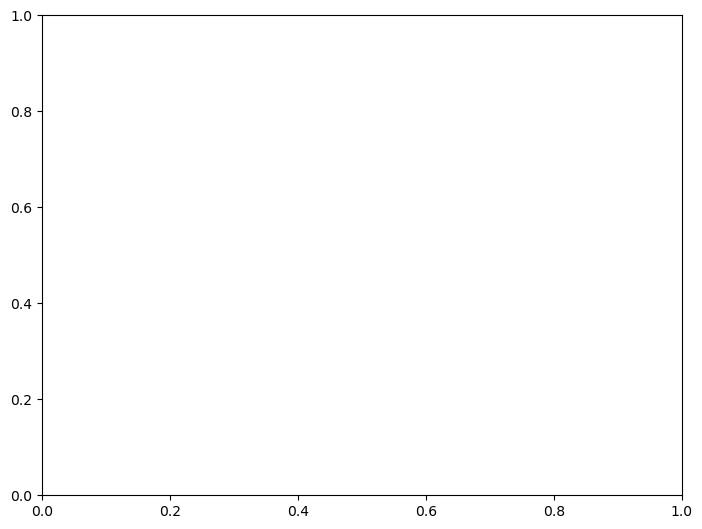

In [9]:
nx.draw(G, node_size=1)

In [ ]:
K=5
sparseA = kneighbors_graph(adata_subset.obsm['X_selected_cell_spatial_tiled'], K, mode='connectivity', include_self=False)
A = sparseA.todense()
G = nx.from_numpy_array(A)
nx.draw(G)

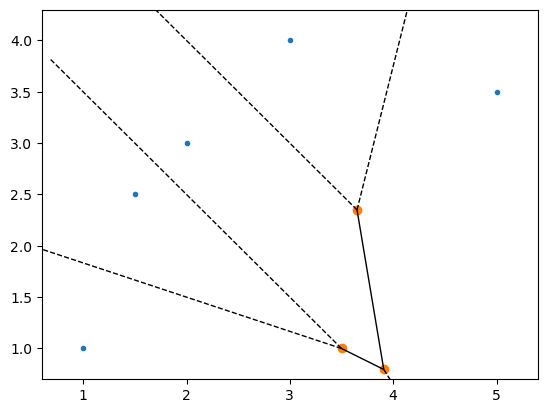

In [1]:
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d

# Example set of points
points = [(1, 1), (1.5, 2.5), (3, 4), (5, 3.5), (2, 3)]

# Compute Voronoi
vor = Voronoi(points)

# Plot
voronoi_plot_2d(vor)
plt.show()
